# **Desigualdade de gênero no ENEM**

**Área de análise:** Pará (PA)  
**Referência territorial:** município da escola (ESC)  
**Período:** 1998–2023 para participação por sexo; 2001–2023 para desempenho; comparação municipal de referência em 2023.

O eixo investiga diferenças de participação e desempenho entre participantes do sexo feminino e masculino no ENEM no Pará. A análise considera a composição dos inscritos, a evolução das diferenças de desempenho, a distribuição territorial e a cobertura dos dados
Uma distinção metodológica deve ser mantida ao longo da leitura: participação é contabilizada pelo número de participantes (`n_participantes`), enquanto desempenho é calculado com notas válidas (`n_validos`). Assim, os totais utilizados nas duas dimensões não são necessariamente iguais.

As médias estaduais apresentadas são ponderadas pelo número de notas válidas. As comparações municipais, por sua vez, descrevem diferenças entre médias calculadas em cada município; não devem ser interpretadas como estatísticas individuais de todos os participantes do Pará.

<div style="background-color: #f0f0f0; padding: 12px; border-radius: 6px;">
 destaque
</div>


## Configuração e carga

In [2]:
from _setup2 import *
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from enem_pipeline.config import (
    PROJECT_ROOT, DATA_DIR, CONSUMO_DIR, UF_PROCESSAMENTO,
    ANO_INICIAL, ANO_FINAL
)
from utils.features_names import read_allfiles2
from utils import eda2

warnings.filterwarnings("ignore", category=FutureWarning)


UF_PROCESSAMENTO = "PA"
TIPO_REFERENCIA = "ESC"
sns.set_theme(style="whitegrid", context="talk")
palette = sns.color_palette("tab10", n_colors=8)


plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 110

out = read_allfiles2(UF_PROCESSAMENTO, TIPO_REFERENCIA)
painel = out["painel"]["data"].copy()
faixa = out["faixa"]["data"].copy()
grupo = out["grupo"]["data"].copy()
shape = out["shape"]["data"].copy()
dsp = out["dsp"]["data"].copy()

print(f"UF: {UF_PROCESSAMENTO} | Referência: {TIPO_REFERENCIA}")
print(f"Painel: {painel.shape} | DSP: {dsp.shape}")
print(f"Anos painel: {painel.ano.min()}–{painel.ano.max()}")
print(f"Anos DSP: {dsp.ano.min()}–{dsp.ano.max()}")

painel_esc = painel.copy()
dsp_esc    = dsp.copy()
# ============================================================
# PARTICIPAÇÃO POR SEXO
# ============================================================

participacao_genero = eda2.calcular_participacao_genero(painel_esc)

participacao_municipal = eda2.calcular_participacao_genero_municipal(painel_esc)

UF: PA | Referência: ESC
Painel: (3625, 82) | DSP: (250436, 17)
Anos painel: 1998–2025
Anos DSP: 2001–2023


## 1. Evolução do número de participantes por sexo

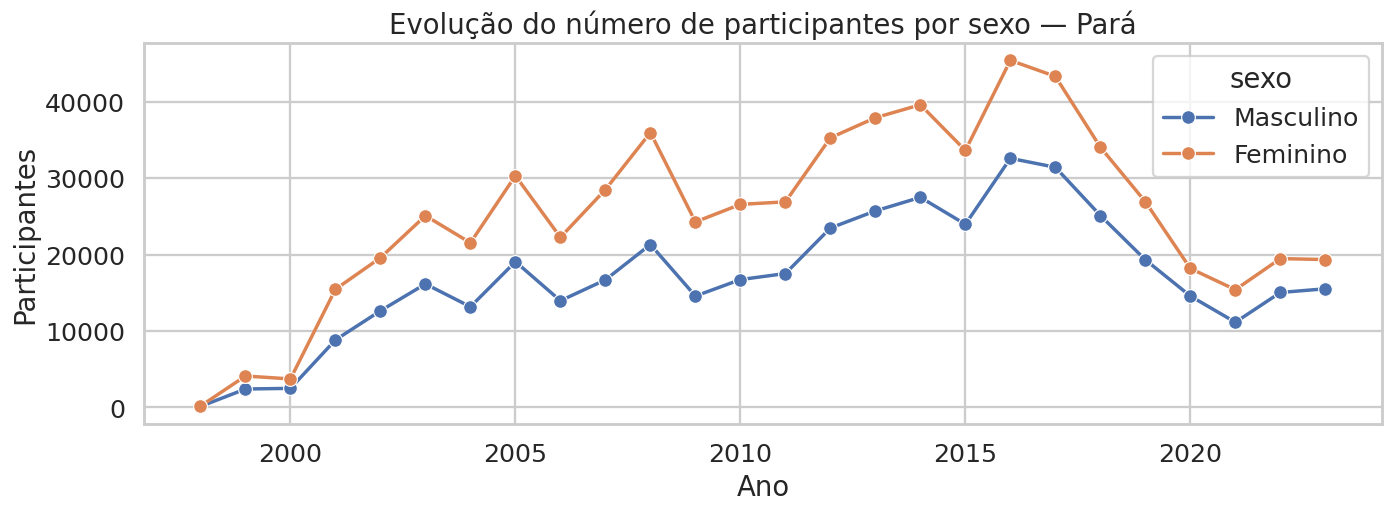

In [3]:
participacao_long = participacao_genero.melt(id_vars=["ano"],value_vars=["masculino", "feminino"],var_name="sexo",value_name="n_participantes")

participacao_long["sexo"] = participacao_long["sexo"].map({"masculino": "Masculino","feminino": "Feminino"})

# Remover anos sem dados de gênero
participacao_long = participacao_long.dropna(subset=["n_participantes"])

fig, ax = plt.subplots(figsize=(13, 5))

sns.lineplot(data=participacao_long,x="ano",y="n_participantes",
             hue="sexo",marker="o",ax=ax)

ax.set(title="Evolução do número de participantes por sexo — Pará",
       xlabel="Ano",
       ylabel="Participantes")

plt.tight_layout()
plt.show()

### Comentários
A participação feminina foi superior à masculina em todos os anos com informação de sexo disponível, entre 1998 e 2023. Entretanto, a diferença entre os grupos diminuiu ao longo da série. Em 2001, as mulheres representavam 63,6% dos participantes, enquanto os homens correspondiam a 36,4%. Em 2023, essas proporções passaram a 55,5% e 44,5%, respectivamente.

| Ano  | Participantes | Feminino | Masculino | Municípios |
| ---- | -------------:| --------:| ---------:| ----------:|
| 1998 | 288           | 58,3%    | 41,7%     | 5          |
| 2001 | 24.295        | 63,6%    | 36,4%     | 116        |
| 2008 | 59.189        | 62,8%    | 37,2%     | 140        |
| 2009 | 38.855        | 62,5%    | 37,5%     | 140        |
| 2016 | 78.031        | 58,2%    | 41,8%     | 143        |
| 2020 | 32.759        | 55,5%    | 44,5%     | 143        |
| 2023 | 34.880        | 55,5%    | 44,5%     | 142        |

A presença feminina permanece majoritária, mas a composição dos participantes tornou-se menos desigual em termos de sexo. A diferença entre as proporções feminina e masculina caiu de 27,3 pontos percentuais em 2001 para 11,0 pontos percentuais em 2023. É importante não confundir essa mudança de composição com uma redução da desigualdade de desempenho. 
Embora o painel geral apresente 71.175 participantes em 2024 e 76.264 em 2025, os campos de sexo não estão disponíveis para esses anos na planilha. Portanto, não é possível estender a comparação por sexo até 2025.


## 2. Evolução da composição percentual por sexo

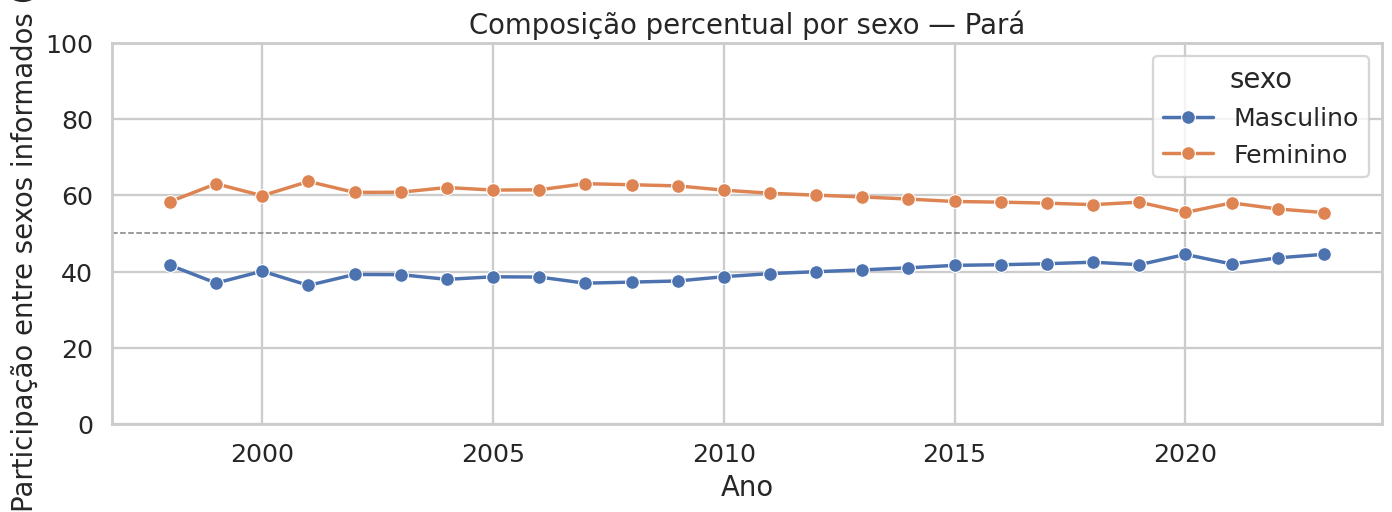

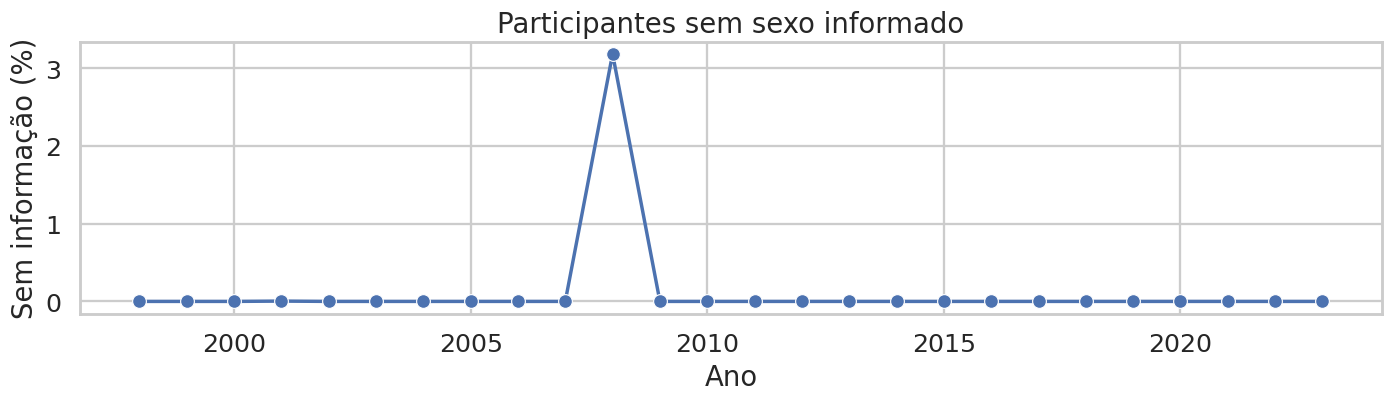

In [4]:
composicao = participacao_genero.melt(id_vars=["ano"], value_vars=["pct_masculino", "pct_feminino"],
                                      var_name="sexo", value_name="percentual")
composicao["sexo"] = composicao["sexo"].map({"pct_masculino": "Masculino", "pct_feminino": "Feminino"})

fig, ax = plt.subplots(figsize=(13, 5))
sns.lineplot(data=composicao, x="ano", y="percentual",
             hue="sexo", marker="o", ax=ax)
ax.axhline(50, color="gray", linestyle="--", linewidth=1)
ax.set(title="Composição percentual por sexo — Pará",
       xlabel="Ano", ylabel="Participação entre sexos informados (%)",
       ylim=(0, 100))
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 4))
sns.lineplot(data=participacao_genero, x="ano",
             y="pct_sexo_nao_informado", marker="o", ax=ax)
ax.set(title="Participantes sem sexo informado",
       xlabel="Ano", ylabel="Sem informação (%)")
plt.tight_layout()
plt.show()



### Comentários
A série percentual confirma uma mudança gradual na composição dos participantes. A participação feminina atingiu valores próximos de 63% no início e em parte da década de 2000. A partir daí, sua proporção diminuiu, enquanto a participação masculina aumentou.

A diferença entre a participação feminina e masculina foi de 27,3 pontos percentuais em 2001. Em 2020 e 2023, essa diferença estava próxima de 11 pontos percentuais.

| Ano  | Feminino | Masculino | Diferença feminino − masculino |
| ---- | --------:| ---------:| ------------------------------:|
| 2001 | 63,6%    | 36,4%     | 27,3 p.p.                      |
| 2008 | 62,8%    | 37,2%     | 25,6 p.p.                      |
| 2009 | 62,5%    | 37,5%     | 25,0 p.p.                      |
| 2016 | 58,2%    | 41,8%     | 16,4 p.p.                      |
| 2020 | 55,5%    | 44,5%     | 11,0 p.p.                      |
| 2023 | 55,5%    | 44,5%     | 11,0 p.p.                      |

Em 2008, 3,2% dos participantes estavam com sexo não informado. Nos demais anos apresentados na tabela, esse percentual foi nulo ou residual. Esse registro deve ser considerado ao interpretar a composição daquele ano.

houve aproximação entre as proporções de participação feminina e masculina. Isso não significa que os dois grupos tenham passado a apresentar o mesmo desempenho, nem permite concluir que a aproximação decorreu de uma causa específica. A análise é descritiva e não identifica os fatores responsáveis pela mudança.


## 3. Diferenças territoriais na composição por sexo

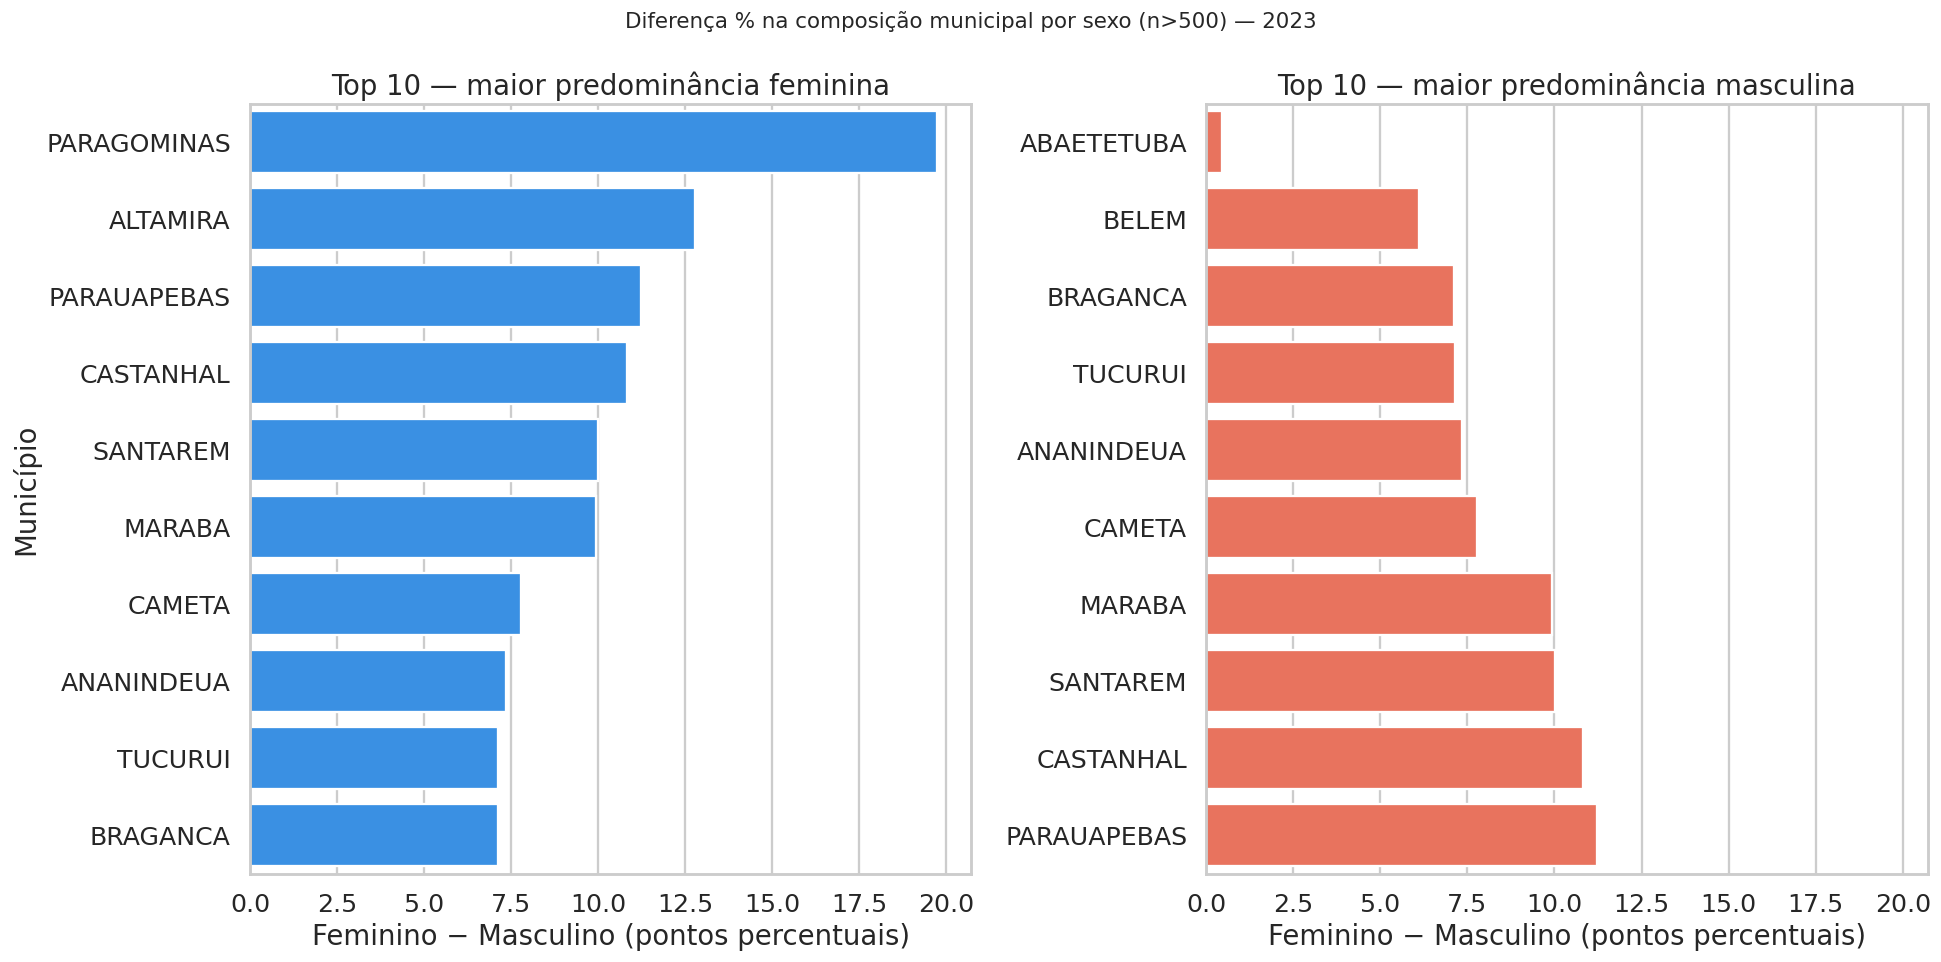

In [13]:
ANO_MUNICIPAL = int(participacao_municipal.loc[participacao_municipal["diferenca_feminino_masculino_pp"].notna(),
        "ano"].max())

municipios_genero = participacao_municipal.loc[
    participacao_municipal.ano.eq(ANO_MUNICIPAL)
].dropna(subset=["diferenca_feminino_masculino_pp"]).copy()

N=500
municipios_genero_fil=municipios_genero[municipios_genero['n_participantes']>N]

df_ord = municipios_genero_fil.sort_values(
    "diferenca_feminino_masculino_pp", ascending=False
)

fig, axes = plt.subplots(1, 2, figsize=(18, 9), sharex=True)

# Esquerda: maior predominância feminina
sns.barplot(
    data=df_ord.head(10),
    x="diferenca_feminino_masculino_pp",
    y="NO_MUNICIPIO_TERRITORIO",
    color="dodgerblue", ax=axes[0]
)
axes[0].set(
    title="Top 10 — maior predominância feminina",
    xlabel="Feminino − Masculino (pontos percentuais)",
    ylabel="Município"
)

# Direita: maior predominância masculina
sns.barplot(
    data=df_ord.tail(10).sort_values("diferenca_feminino_masculino_pp"),
    x="diferenca_feminino_masculino_pp",
    y="NO_MUNICIPIO_TERRITORIO",
    color="tomato", ax=axes[1]
)
axes[1].set(
    title="Top 10 — maior predominância masculina",
    xlabel="Feminino − Masculino (pontos percentuais)",
    ylabel=""
)

for ax in axes:
    ax.axvline(0, color="black", linewidth=1)

fig.suptitle(
    f"Diferença % na composição municipal por sexo (n>500) — {ANO_MUNICIPAL}",
    fontsize=14
)
plt.tight_layout()
plt.show()

# display(municipios_genero_fil.sort_values(
#     "diferenca_feminino_masculino_pp", ascending=False
# )[[
#     "NO_MUNICIPIO_TERRITORIO", "n_participantes",
#     "n_masculino", "n_feminino", "pct_masculino", "pct_feminino",
#     "diferenca_feminino_masculino_pp", "pct_sexo_nao_informado"
# ]].head(40))

### Comentarios

A participação feminina foi superior à masculina no agregado estadual, mas a intensidade dessa diferença variou entre os municípios.

Entre os municípios com maior número de participantes( não confundir com gráfico acima) destacam-se:

| Município   | Participantes | Feminino | Masculino |
| ----------- | -------------:| --------:| ---------:|
| Belém       | 8.574         | 53,1%    | 46,9%     |
| Ananindeua  | 2.759         | 53,7%    | 46,3%     |
| Santarém    | 1.769         | 55,0%    | 45,0%     |
| Marabá      | 1.421         | 55,0%    | 45,0%     |
| Castanhal   | 1.191         | 55,4%    | 44,6%     |
| Parauapebas | 1.113         | 55,6%    | 44,4%     |
| Abaetetuba  | 878           | 50,2%    | 49,8%     |
| Tucuruí     | 659           | 53,6%    | 46,4%     |

A mediana municipal da participação feminina foi de aproximadamente 57,5%. Entretanto, a distribuição entre municípios é heterogênea: há municípios com participação feminina muito elevada e outros nos quais a participação masculina é maior.

A predominância feminina observada no total estadual também aparece em muitos municípios, mas não de maneira uniforme. Em alguns territórios, a composição por sexo aproxima-se do equilíbrio ou apresenta predominância masculina. Percentuais municipais calculados sobre poucos participantes podem variar bastante. Por isso, diferenças extremas em municípios com baixa quantidade de registros não devem ser interpretadas como padrões territoriais consolidados. A comparação deve considerar simultaneamente os percentuais e o número de participantes.


## 4. Evolução do desempenho por sexo e disciplina

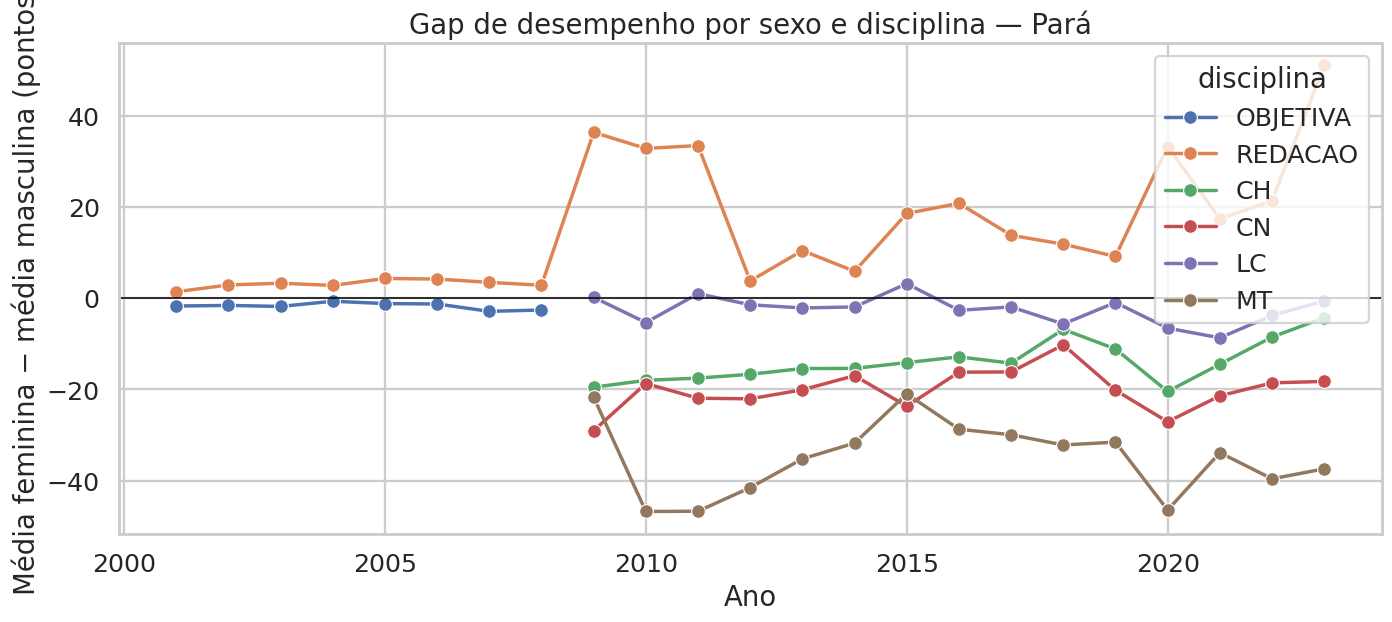

In [6]:

desempenho_genero = eda2.calcular_desempenho_genero(dsp_esc)
gap_desempenho = eda2.calcular_gap_desempenho_genero(desempenho_genero)

#display(desempenho_genero) #.head(50))
#display(gap_desempenho)
fig, ax = plt.subplots(figsize=(13, 6))
sns.lineplot(data=gap_desempenho, x="ano",
             y="gap_feminino_masculino", hue="disciplina",
             marker="o", ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Gap de desempenho por sexo e disciplina — Pará",
       xlabel="Ano", ylabel="Média feminina − média masculina (pontos)")
plt.tight_layout()
plt.show()

### Comparabilidade histórica das séries de desempenho

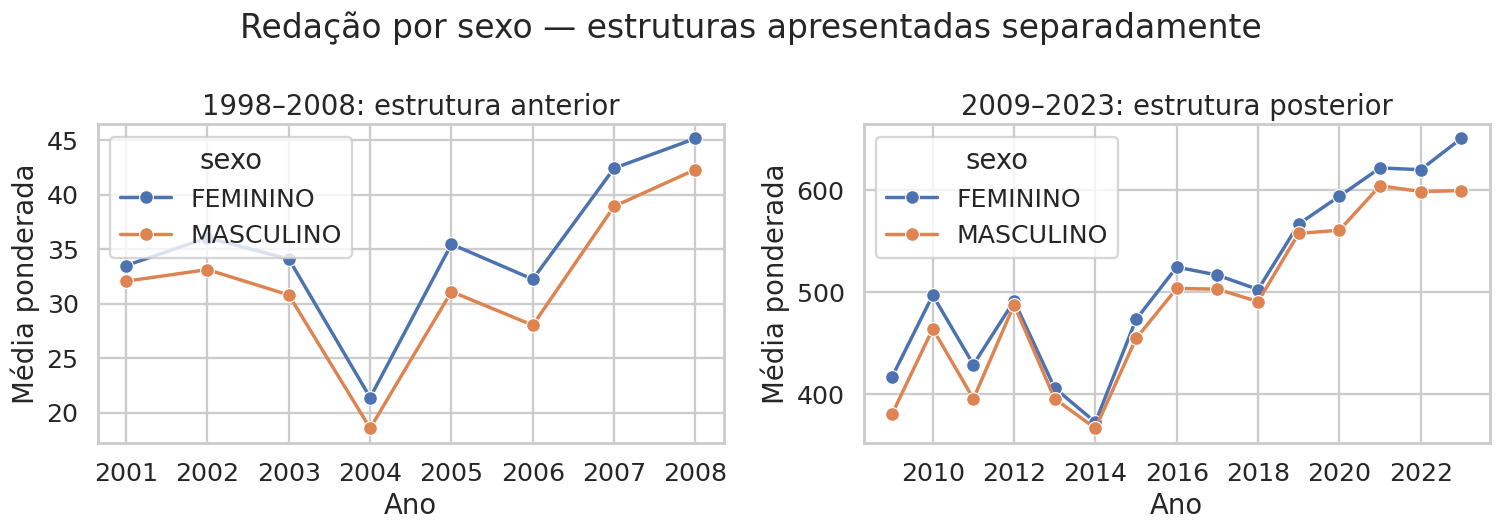

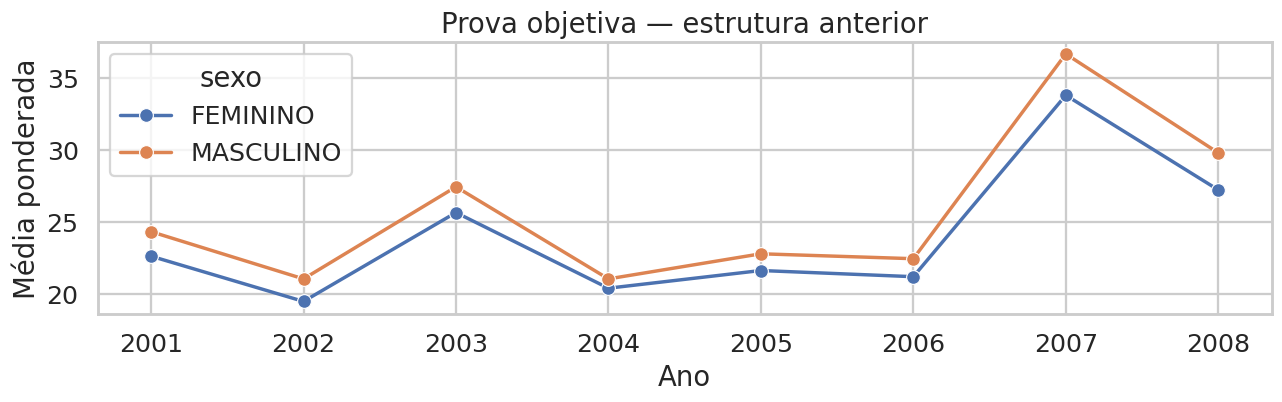

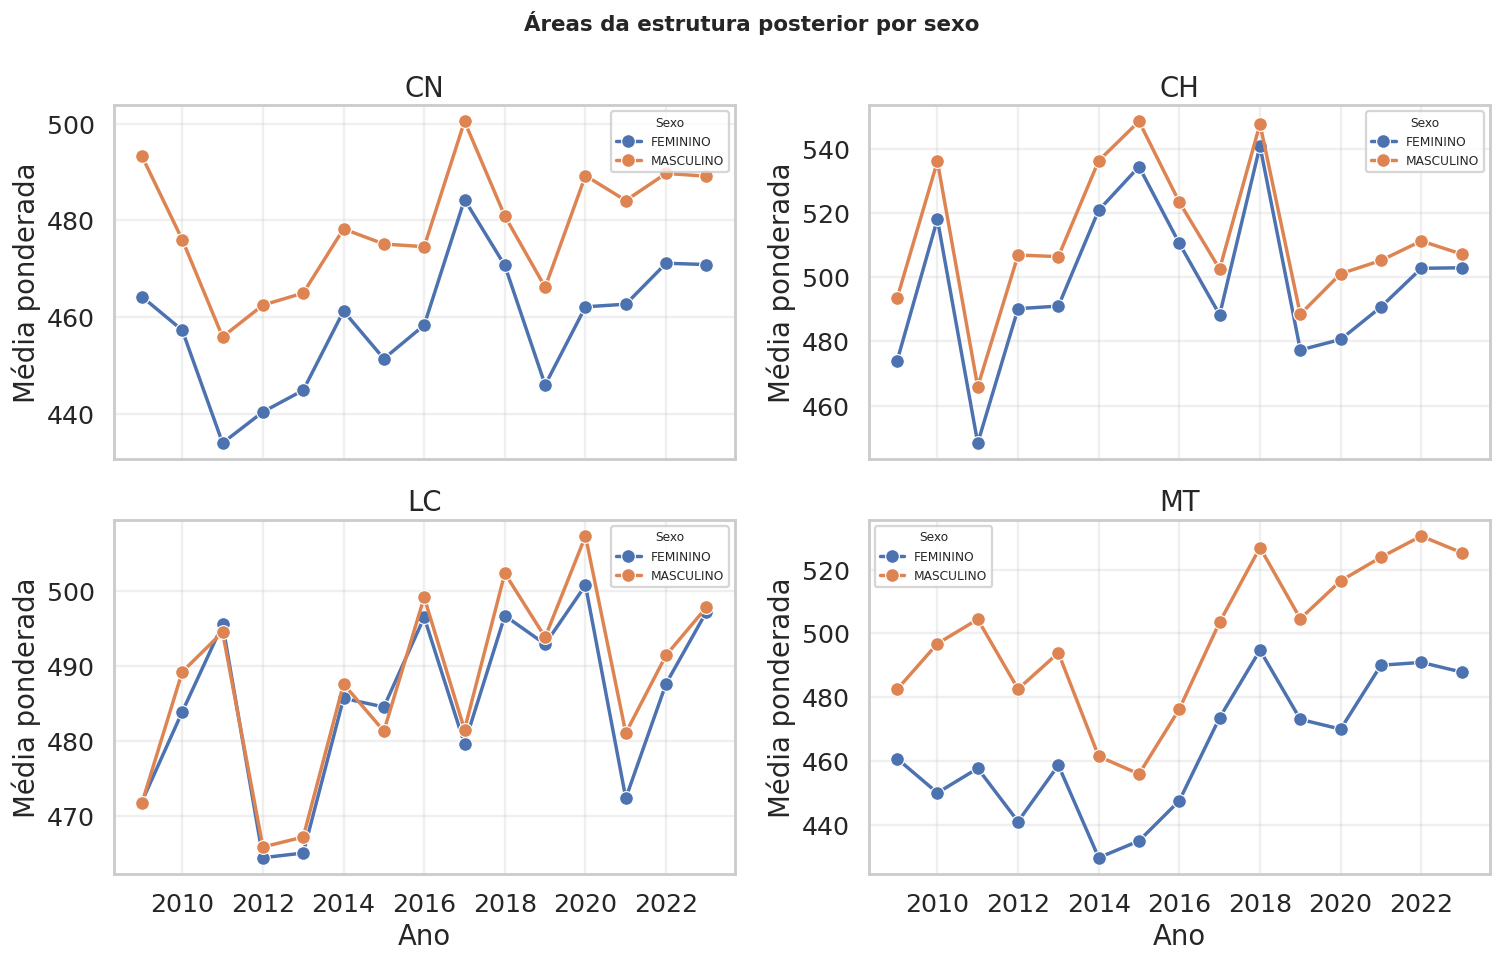

In [7]:
disciplinas = set(desempenho_genero.disciplina.dropna().unique())

if "REDACAO" in disciplinas:
    red = desempenho_genero.loc[desempenho_genero.disciplina.eq("REDACAO")].copy()
    red["estrutura"] = np.where(red.ano <= 2008, "1998–2008: estrutura anterior",
                                "2009–2023: estrutura posterior")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, periodo in zip(axes, [
        "1998–2008: estrutura anterior", "2009–2023: estrutura posterior"
    ]):
        sns.lineplot(data=red.loc[red.estrutura.eq(periodo)],
                     x="ano", y="media_ponderada", hue="sexo",
                     marker="o", ax=ax)
        ax.set(title=periodo, xlabel="Ano", ylabel="Média ponderada")
    fig.suptitle("Redação por sexo — estruturas apresentadas separadamente")
    plt.tight_layout()
    plt.show()

if "OBJETIVA" in disciplinas:
    obj = desempenho_genero.loc[desempenho_genero.disciplina.eq("OBJETIVA")]
    fig, ax = plt.subplots(figsize=(12, 4))
    sns.lineplot(data=obj, x="ano", y="media_ponderada",
                 hue="sexo", marker="o", ax=ax)
    ax.set(title="Prova objetiva — estrutura anterior",
           xlabel="Ano", ylabel="Média ponderada")
    plt.tight_layout()
    plt.show()

areas = [x for x in disciplinas if x in {
    "CN", "CH", "LC", "MT", "CN (Ciências da Natureza)",
    "CH (Ciências Humanas)", "LC (Linguagens e Códigos)", "MT (Matemática)"
}]
if areas:
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
    axes = axes.ravel()

    # Ordem fixa das áreas (mesma usada na lista 'areas' filtrada)
    ordem_areas = [a for a in [
        "CN", "CH", "LC", "MT",
        "CN (Ciências da Natureza)", "CH (Ciências Humanas)",
        "LC (Linguagens e Códigos)", "MT (Matemática)"
    ] if a in areas]

    for ax, area in zip(axes, ordem_areas):
        sub = desempenho_genero.loc[desempenho_genero.disciplina.eq(area)]
        sns.lineplot(data=sub, x="ano", y="media_ponderada",
                     hue="sexo", marker="o", ax=ax)
        ax.set(title=area, xlabel="Ano", ylabel="Média ponderada")
        ax.grid(alpha=0.3)
        ax.legend(title="Sexo", fontsize=8, title_fontsize=8)

    # Esconde eixos sobrando (caso áreas < 4)
    for ax in axes[len(ordem_areas):]:
        ax.set_visible(False)

    fig.suptitle("Áreas da estrutura posterior por sexo", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


### Comentários
As diferenças de desempenho variam conforme a disciplina. Para interpretar os resultados, o indicador utilizado é:

**Gap = média feminina − média masculina.**

Assim, valores positivos indicam média feminina superior; valores negativos indicam média masculina superior.

No período anterior a 2009, a média masculina foi superior na prova objetiva, enquanto a média feminina foi superior na Redação. A partir de 2009, com a reorganização do ENEM, a comparação passa a considerar CH, CN, LC, MT e Redação.

Em 2023, os resultados foram:

| Disciplina | Média feminina | Média masculina | Gap feminino − masculino |
| ---------- | --------------:| ---------------:| ------------------------:|
| CH         | 502,9          | 507,2           | -4,3                     |
| CN         | 470,9          | 489,1           | -18,2                    |
| LC         | 497,2          | 497,8           | -0,6                     |
| MT         | 487,9          | 525,3           | -37,4                    |
| Redação    | 650,7          | 599,6           | +51,1                    |

Em 2023, os homens apresentaram médias superiores em Ciências Humanas, Ciências da Natureza e Matemática. Em Linguagens, as médias foram muito próximas. Na Redação, a média feminina foi superior em aproximadamente 51 pontos. A maior diferença favorável aos homens ocorreu em Matemática. A maior diferença favorável às mulheres ocorreu em Redação. Portanto, não existe uma única direção de vantagem entre os grupos: o resultado depende da área avaliada.


## 5. Diferenças de desempenho entre municípios 2023

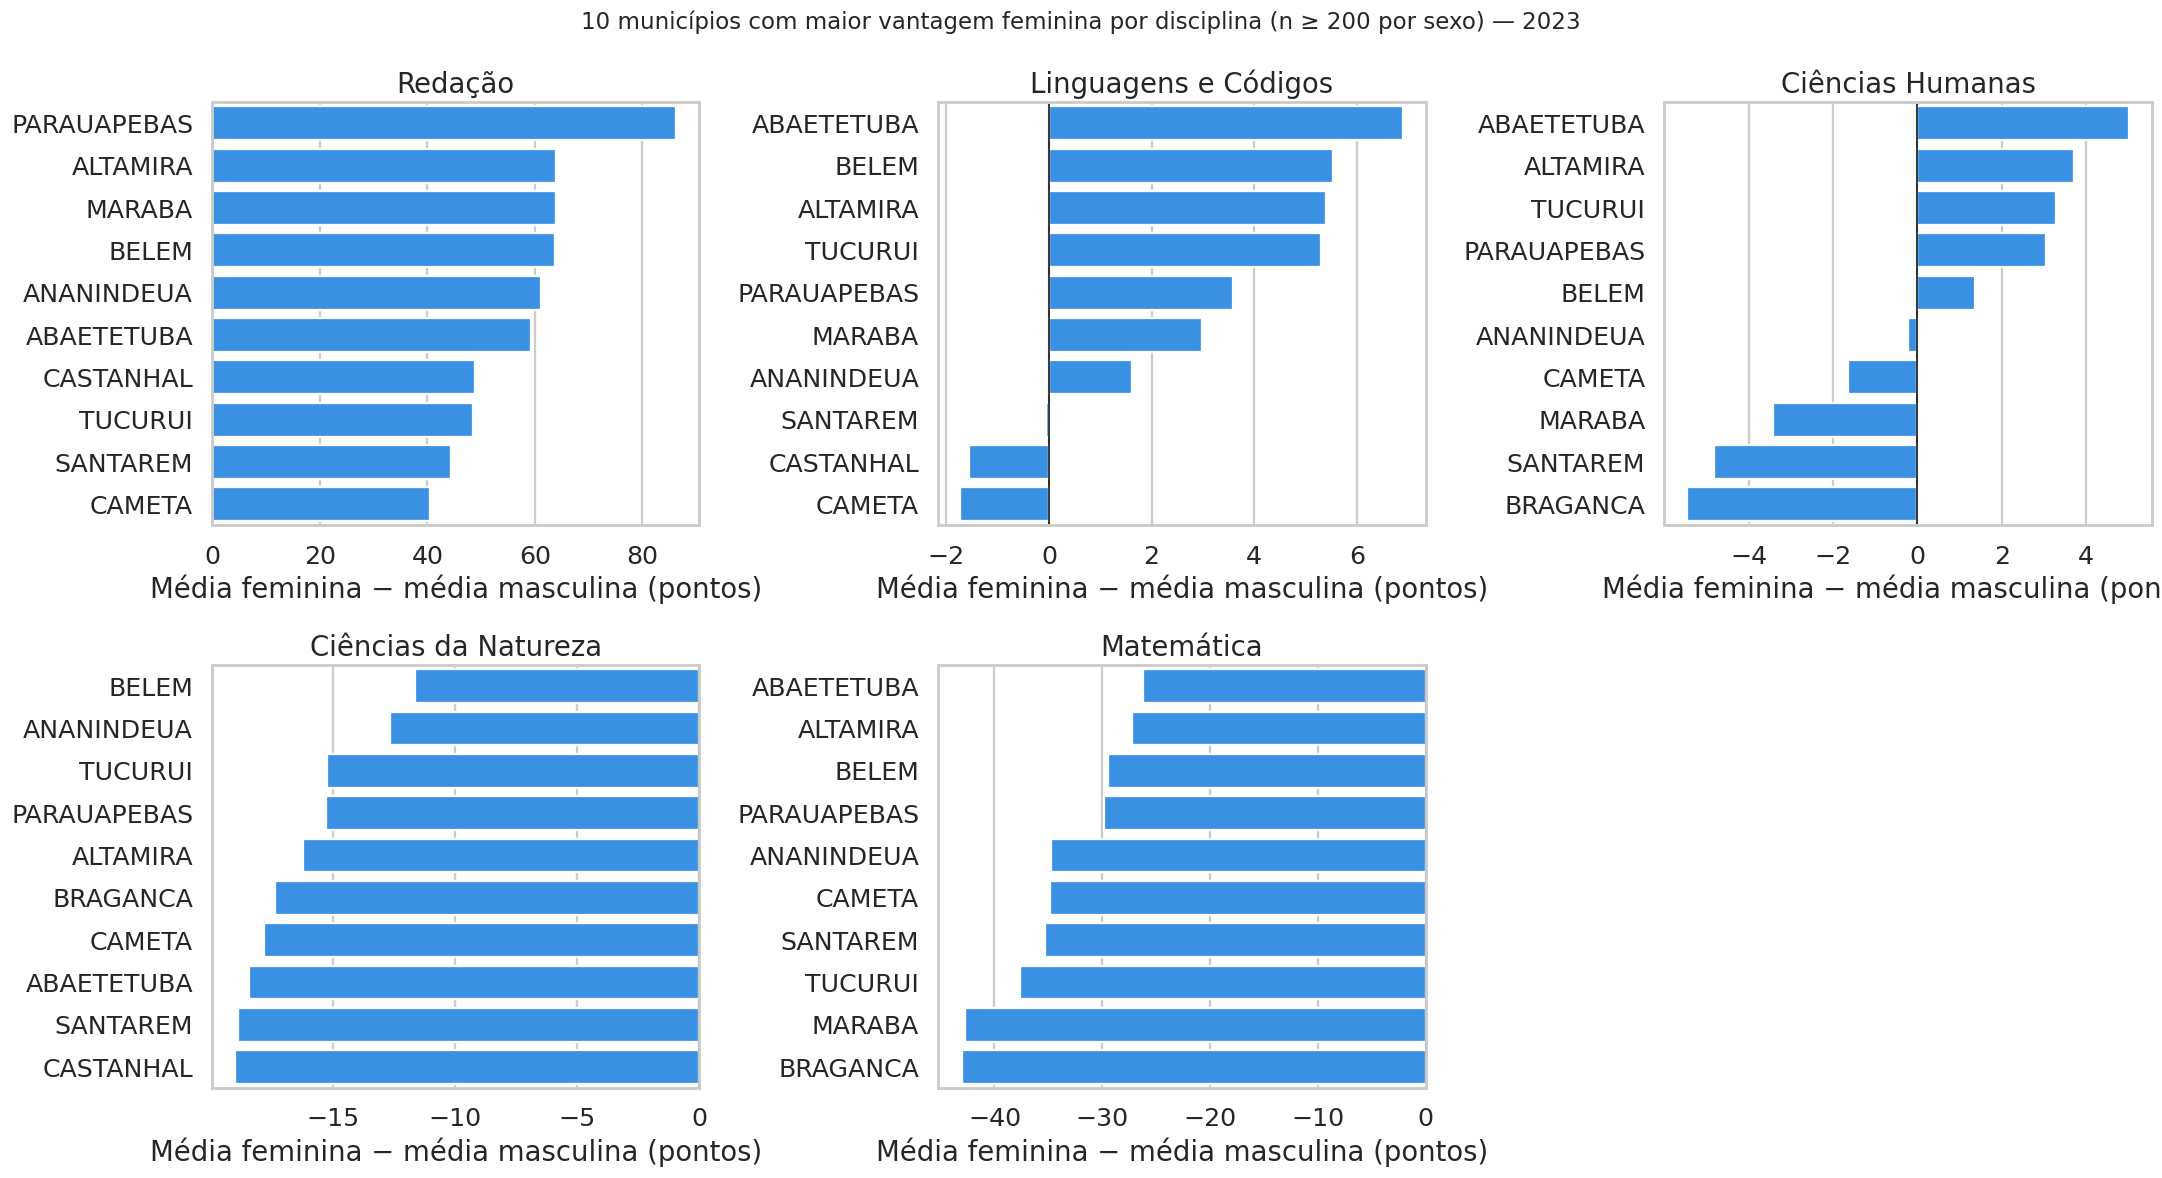

In [62]:
ANO_DSP_FINAL = int(dsp_esc.ano.max()) #2023

N_MINIMO_VALIDOS_SEXO = 200  # critério operacional de apresentação

desempenho_municipal = eda2.calcular_desempenho_genero(dsp_esc, por_municipio=True)
gap_municipal = eda2.calcular_gap_desempenho_genero(desempenho_municipal, por_municipio=True)
gap_municipal_ano = gap_municipal.loc[gap_municipal.ano.eq(ANO_DSP_FINAL)].copy()

gap_municipal_ano["elegivel"] = (
    gap_municipal_ano.n_validos_feminino.ge(N_MINIMO_VALIDOS_SEXO)& 
    gap_municipal_ano.n_validos_masculino.ge(N_MINIMO_VALIDOS_SEXO))
pd.set_option('display.max_rows', None)

#display(gap_municipal_ano[gap_municipal_ano['elegivel']==True])
# disciplinas_ano = sorted(gap_municipal_ano.disciplina.dropna().unique())


ORDEM_DISCIPLINAS = ["REDACAO", "LC", "CH", "CN", "MT"]
NOMES = {
    "REDACAO": "Redação",
    "LC": "Linguagens e Códigos",
    "CH": "Ciências Humanas",
    "CN": "Ciências da Natureza",
    "MT": "Matemática",
}

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()

for ax, disc in zip(axes, ORDEM_DISCIPLINAS):
    plot_df = (
        gap_municipal_ano
        .loc[gap_municipal_ano.disciplina.eq(disc) & gap_municipal_ano.elegivel]
        .nlargest(10, "gap_feminino_masculino")
    )

    if plot_df.empty:
        ax.set_title(f"{NOMES[disc]} — sem municípios elegíveis")
        ax.axis("off")
        continue

    sns.barplot(
        data=plot_df,
        x="gap_feminino_masculino",
        y="NO_MUNICIPIO_TERRITORIO",
        color="dodgerblue",
        ax=ax
    )
    #display(plot_df)
    ax.axvline(0, color="black", linewidth=1)
    ax.set(
        title=NOMES[disc],
        xlabel="Média feminina − média masculina (pontos)",
        ylabel=""
    )

# esconde o 6º painel (não usado)
for ax in axes[len(ORDEM_DISCIPLINAS):]:
    ax.axis("off")

fig.suptitle(
    f"10 municípios com maior vantagem feminina por disciplina "
    f"(n ≥ {N_MINIMO_VALIDOS_SEXO} por sexo) — {ANO_DSP_FINAL}",
    fontsize=15
)
plt.tight_layout()
plt.show()

### comentarios
A comparação municipal de desempenho por sexo foi realizada para 2023, adotando o critério mínimo de 200 participantes válidos em cada grupo (feminino e masculino). Esse critério busca reduzir a influência de médias calculadas sobre grupos com baixa representatividade, embora restrinja o conjunto de municípios considerados.

A mediana municipal do gap foi:

| Disciplina | Municípios elegíveis | Gap mediano (feminino − masculino) |
| ---------- | --------------------:| ----------------------------------:|
| CH         | 10                   | +0.58                              |
| CN         | 10                   | -16,81                             |
| LC         | 10                   | -3.29                              |
| MT         | 10                   | -34.79                             |
| Redação    | 10                   | +60.17                             |


Os resultados apresentados evidenciam diferenças distintas conforme a disciplina. Em Ciências Humanas (CH) e Linguagens (LC), os gaps são relativamente pequenos e apresentam variações de sinal entre municípios, indicando que as diferenças de desempenho entre homens e mulheres são pouco expressivas em parte dos casos analisados.

Em Ciências da Natureza (CN) e, principalmente, em Matemática (MT), observa-se predominância de gaps negativos, indicando médias masculinas superiores às femininas nos municípios apresentados. Em Matemática, as diferenças são mais expressivas, alcançando aproximadamente 43 pontos em alguns municípios. A Redação apresenta o padrão oposto: os gaps são positivos e expressivos nos municípios apresentados, indicando vantagem feminina.

Também é interessante observar que a magnitude do gap varia entre municípios.

- Em **Redação**, Parauapebas apresenta uma diferença particularmente elevada (+86,28), enquanto Cametá apresenta uma diferença menor (+40,56).
- Em **Matemática**, Bragança (-43,06) e Marabá (-42,69) apresentam diferenças expressivas, enquanto Abaetetuba (-26,21) apresenta uma diferença menor.
- Em **LC e CH**, as diferenças são menores e podem mudar de sinal entre municípios.
  
Isso pode indicar que as diferenças entre os grupos não são  homogêneas no território paraense. Assim as diferenças de desempenho por sexo apresentam variação territorial e dependem da disciplina considerada. O padrão observado aponta vantagem masculina em Matemática e Ciências da Natureza, enquanto em Redação a vantagem feminina é expressiva. Em Ciências Humanas e Linguagens, as diferenças são menores e menos uniformes entre municípios.






## 6. cobertura territorial e amostral 

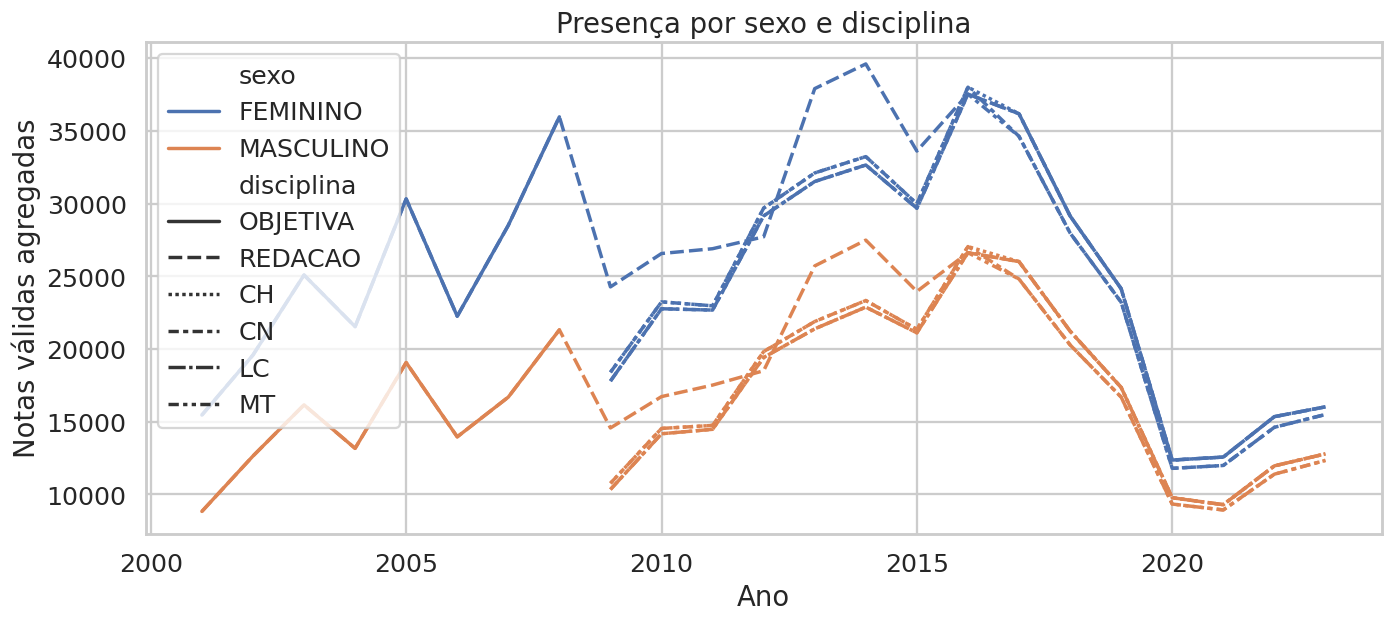

In [66]:
cobertura_sexo_disciplina = dsp_esc.loc[
    dsp_esc.sexo.astype("string").str.upper().isin(["MASCULINO", "FEMININO"])
].groupby(["ano", "disciplina", "sexo"], as_index=False).agg(
    n_municipios=("CO_MUNICIPIO_TERRITORIO", "nunique"),
    n_validos=("n_validos", "sum"),
    n_registros=("n_validos", "size"),
)

#display(cobertura_sexo_disciplina)
#display(cobertura_sexo_disciplina.sort_values(["ano", "disciplina", "sexo"]))

fig, ax = plt.subplots(figsize=(13, 6))
sns.lineplot(data=cobertura_sexo_disciplina, x="ano", y="n_validos",
             hue="sexo", style="disciplina", dashes=True, ax=ax)
ax.set(title="Presença por sexo e disciplina",
       xlabel="Ano", ylabel="Notas válidas agregadas")
plt.tight_layout()
plt.show()

### Comentarios

A cobertura territorial das análises varia ao longo dos anos e entre os grupos feminino e masculino. Em 2001, foram identificados 111 municípios com notas válidas femininas e 113 com notas válidas masculinas. Em 2009, a cobertura alcançou 139 municípios para mulheres e 138 para homens nas cinco disciplinas. Em 2020, foram registrados 142 municípios para ambos os grupos, enquanto em 2023 a cobertura foi de 141 municípios para cada grupo.

| Ano  | Municípios com notas válidas femininas | Municípios com notas válidas masculinas |
| ---- | -------------------------------------- | --------------------------------------- |
| 2001 | 111                                    | 113                                     |
| 2009 | 139                                    | 138                                     |
| 2020 | 142                                    | 142                                     |
| 2023 | 141                                    | 141                                     |

Em 2023, a quantidade de notas válidas variou conforme a disciplina. Para CH, LC e Redação, foram contabilizadas 16.027 notas válidas femininas e 12.792 masculinas. Para CN e MT, foram registradas 15.499 notas válidas femininas e 12.342 masculinas.

A cobertura territorial dos dados é ampla nos anos recentes, alcançando aproximadamente 140 municípios. Entretanto, a quantidade de municípios com notas válidas e o volume de observações variam conforme o período, o grupo analisado e a disciplina. Essas diferenças devem ser consideradas na interpretação dos resultados e nas comparações entre os grupos.

A cobertura territorial e amostral não deve ser confundida com o número total de participantes. A análise baseada em notas considera os registros com valores válidos na disciplina correspondente, enquanto a análise de participação utiliza os registros de participantes.



## 7. Síntese dos resultados

O conjunto dos resultados mostra que as desigualdades de gênero no ENEM no Pará se manifestam de maneiras distintas na participação e nas médias obtidas nas provas.

A primeira constatação é a predominância feminina na participação durante todo o período com informação disponível, de 1998 a 2023. Entretanto, essa predominância diminuiu ao longo do tempo: a diferença entre as proporções feminina e masculina passou de 27,3 pontos percentuais em 2001 para aproximadamente 11 pontos percentuais em 2023.

A segunda constatação é que a participação feminina majoritária não corresponde a uma vantagem feminina em todas as disciplinas. Em 2023, os homens apresentaram médias superiores em CH, CN e MT, enquanto as mulheres tiveram média superior em Redação. Em LC, a diferença foi pequena. Esse padrão evidencia que as diferenças entre os grupos variam conforme a área do conhecimento.

A análise histórica reforça essa interpretação. Desde 2009, a vantagem masculina aparece de forma recorrente em Matemática e Ciências da Natureza, embora sua magnitude varie. Em Linguagens, as diferenças são geralmente menores e alternam de direção. Na Redação, a média feminina foi superior em todos os anos observados a partir de 2009, com variações na magnitude da diferença.

No território, os resultados de 2023 mostram que as diferenças entre as médias femininas e masculinas variam entre os municípios e as disciplinas. Nos municípios apresentados, Redação registrou diferenças positivas em favor das mulheres, enquanto Ciências da Natureza e Matemática apresentaram diferenças negativas em favor dos homens. Em Linguagens e Ciências Humanas, as diferenças foram menores e variaram de direção entre os municípios. A recorrência de determinados municípios nos rankings das diferentes disciplinas também evidencia que alguns territórios aparecem de forma consistente nas comparações, embora a magnitude e a direção das diferenças dependam da área avaliada.

Por fim, a cobertura territorial e o número de notas válidas variam conforme o ano e a disciplina. Em 2023, foram identificados 141 municípios com notas válidas para ambos os grupos. A quantidade de notas válidas também variou entre as disciplinas. Nas comparações municipais, a adoção do critério mínimo de 200 notas válidas por sexo torna a análise mais restritiva, reduzindo o conjunto de municípios elegíveis. Assim, os resultados municipais devem ser interpretados considerando esse recorte amostral.

<div style="background-color: #f0f0f0; padding: 12px; border-radius: 6px;">

**Em resumo, as mulheres constituem a maioria dos participantes do ENEM no Pará, embora essa diferença de participação tenha diminuído ao longo da série. Nas médias das provas, não há uma vantagem única para um dos grupos: os homens apresentam médias superiores em algumas áreas, especialmente Matemática, enquanto as mulheres apresentam vantagem expressiva em Redação. Essas diferenças também variam entre os municípios. Portanto, as desigualdades de gênero no ENEM devem ser compreendidas considerando conjuntamente a participação, a disciplina avaliada, o território e a cobertura dos dados**
</div>
